# Computer Vision Assignments: Sessions 1 & 2

This notebook contains tasks and assignments based on Sessions 1 and 2. You are required to implement the functions and complete the exercises as described. Use OpenCV and other necessary libraries like NumPy and Matplotlib.

**Instructions:**
- Complete each task in the provided code cells.
- Test your implementations with sample images (e.g., download test images [here](https://sipi.usc.edu/database/database.php?volume=misc) or [here](https://www.hlevkin.com/hlevkin/06testimages.htm) or use your own test images).
- Include comments in your code for clarity.
- Display results using cv2.imshow() or Matplotlib where appropriate.
- Submit the completed notebook along with any output images or explanations on [our google drive for the CV sessions](https://drive.google.com/drive/folders/1IjVhJmAXxNQTGT-ybJ-yc5smYtR5v8CO?usp=sharing) **upload your files in a new folder under your name**

## Session 1: Basic Image Operations (Reading, Resizing, Cropping, Rotating)

### Task 1: Read and Display an Image
Read an image from a file and display it in both BGR and grayscale formats. Handle errors if the image cannot be read.

In [2]:
import cv2 as cv
import sys
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# Your code here
path = r'C:\Users\habib\OneDrive\Desktop\gettingintoit\skyexperts CV training\Session1\images\dog2.JPG'
# Read in BGR
img_def= cv.imread(path)

# Read in Grayscale
img_grey= cv.imread(path, 0) #0 is the flag for greyscale display, 1 is the default for bgr

# Display both using cv.imshow() or plt.imshow()
cv.imshow("dog image", img_def)
cv.waitKey(3000)
cv.destroyAllWindows

cv.imshow("grey dog image", img_grey)
cv.waitKey(3000)

cv.destroyAllWindows()


### Task 2: Resize Image with Aspect Ratio Preservation
Implement resizing while preserving aspect ratio. Downscale to 60% and upscale to 200%. Compare shapes and display originals vs resized.

In [3]:
# Your code here
# Load image
path= r'C:\Users\habib\OneDrive\Desktop\gettingintoit\skyexperts CV training\Session1\images\dog.jpg'
img=cv.imread(path)

# Downscale to 60%
h, w, _ = img.shape #notice that this method returns the heigth first (numpy)
                     #while opencv will read the width first, so the dim variable tuple starts with w then h

d_scale=60

dh= int (d_scale* h/100)
dw= int (w* d_scale/100)
ddim=(dw, dh)

down= cv.resize(img, ddim, interpolation=cv.INTER_AREA)
# Upscale to 200%

u_scale=200
uh= int(h*u_scale /100)
uw= int(w*u_scale /100)
udim=(uw, uh)
up=cv.resize(img, udim)


# Display all three
cv.imshow('down scaled', down)
cv.waitKey(2000)

cv.imshow('up scaled', up)
cv.waitKey(2000)

cv.destroyAllWindows()

### Task 3: Resize Without Preserving Aspect Ratio
Resize only width to 100 pixels, only height to 200 pixels, and both to (200, 200). Display and discuss distortions.

In [4]:
# Your code here
resized_w= (100, h)
resized_h= (w, 200)
both_resized= (200, 200)

resized_img_w= cv.resize(img, resized_w, interpolation=cv.INTER_AREA)
resized_img_h= cv.resize(img, resized_h, interpolation=cv.INTER_AREA)
resized_img_both =cv.resize(img, both_resized, interpolation=cv.INTER_AREA)

cv.imshow('w resized', resized_img_w)
cv.waitKey(1000)

cv.imshow('h resized', resized_img_h)
cv.waitKey(1000)

cv.imshow('both dimensions resized', resized_img_both)
cv.waitKey(1000)

cv.imshow('original', img)
cv.waitKey(4000)


cv.destroyAllWindows()


the first is stretched vertically as we reduced the width and maintained the height as original,
while the second image is stretched horizontally as the opposite happened.

the third seems like the original one but smaller because the resizing arguments are both less than the original shape

### Task 4: Resize Using Scale Factors (fx, fy)
Scale up by 1.2 in both directions and down by 0.6. Use different interpolations (INTER_LINEAR, INTER_NEAREST) and compare quality.

In [5]:
# Your code here
up_x= up_y= 1.2
down_x=down_y=0.6

#scaled up
cv.imshow(
      'up scaled image',
       cv.resize(img, None, fx= up_x, fy= up_y, interpolation=cv.INTER_LINEAR)
       )
cv.waitKey(500)

#scaled down
cv.imshow(
    'down scaled image',
    cv.resize(img, None, fx= down_x, fy= down_y, interpolation=cv.INTER_LINEAR)
)
cv.waitKey(500)



-1

In [6]:
# Experiment with interpolations
cv.imshow(
      'up scaled image',
       cv.resize(img, None, fx= up_x, fy= up_y, interpolation=cv.INTER_NEAREST)
       )
cv.waitKey(500)

#scaled down
cv.imshow(
    'down scaled image',
    cv.resize(img, None, fx= down_x, fy= down_y, interpolation=cv.INTER_NEAREST)
)
cv.waitKey(500)

cv.imshow('original', img)
cv.waitKey(5000)

cv.destroyAllWindows()

side notes for later notebook reviewing:(each interpolation method and when it's better to use it)
1. INTER_NEAREST: Copies the single closest original pixel, good for blocky or jagged, especially when upscaling but faster
2. INTER_LINEAR (default): Weighted average of the 4 nearest pixels, good for General use and upscaling
3. INTER_AREA: Averages all original pixels that "fall into" each new pixel, good for Downscaling
4. INTER_CUBIC: Uses the 16 nearest pixels (4×4) with a smooth curve, good for Better-looking upscaling, but slower

#revise this code snippet later, there's somehting wrong apparently abt it


### Task 5: Cropping an Image
Crop a region (e.g., [20:200, 50:200]) from the image. Display original and cropped.

In [7]:
# Your code here
cropped= img[20:200, 50:200]
cv.imshow('cropped image', cropped)
cv.waitKey(2000)
cv.destroyAllWindows()

side note: 
this slicing represents: img[y_start : y_end,  x_start : x_end] i.e columns start: end, rows start: end
and the area where they overlap is the cropped image we want





### Task 6: Advanced Cropping - Patch Image into Blocks
Divide the image into 4 equal blocks (2x2 grid) by cropping. Display each block separately and then stitch them back using NumPy concatenation to verify.

In [8]:
rows, cols = 2, 2
#basic problem solving:
chunks = []
for i in range(rows):
    y_start = i * h // rows
    y_end = (i + 1) * h // rows
    row_pieces = []
    for j in range(cols):
        x_start = j * w // cols
        x_end = (j + 1) * w // cols
        row_pieces.append(img[y_start:y_end, x_start:x_end])
    chunks.append(row_pieces)

# Display each
for i in range(rows):
    for j in range(cols):
        cv.imshow(f'chunk {i},{j}', chunks[i][j])

stitched = np.vstack([np.hstack(row_pieces) for row_pieces in chunks])

cv.imshow('stitched', stitched)
print("same as original:", np.array_equal(stitched, img))

cv.waitKey(4000)
cv.destroyAllWindows()


same as original: True


### Task 7: Rotating an Image
Rotate the image by 45°, 90°, and 180° using getRotationMatrix2D and warpAffine. Display all rotations.

In [9]:
# Your code here
# Calculate center
center= (w/2, h/2)

rot_mat_45 =cv.getRotationMatrix2D(center=center, angle=45, scale=1)
rot_mat_90=cv.getRotationMatrix2D(center=center, angle=90, scale=1)
rot_mat_180=cv.getRotationMatrix2D(center=center, angle=180, scale=1)


# For each angle: get matrix, warp, display
rot_45= cv.warpAffine(img, rot_mat_45, (w, h))
rot_90= cv.warpAffine(img, rot_mat_90, (w, h))
rot_180=cv.warpAffine(img, rot_mat_180, (w, h))

cv.imshow("45", rot_45)
cv.imshow("90", rot_90)
cv.imshow("180", rot_180)

cv.waitKey(3000)
cv.destroyAllWindows()

### Task 8: Rotate with Scaling
Rotate by 45° and scale by 0.5 in **one** operation. Compare with separate resize and rotate.

In [10]:
# Your code here
rot_mat_45 =cv.getRotationMatrix2D(center=center, angle=45, scale=0.5)
rot_45= cv.warpAffine(img, rot_mat_45, (w, h))
cv.imshow("45", rot_45)
cv.waitKey(3000)
cv.destroyAllWindows()


## Session 2: Image Acquisition, Formats, Color Spaces, Enhancement, and Filtering

### Task 9: Read Image in Different Color Spaces
Read an image in BGR, convert to RGB (for Matplotlib), HSV, LAB and Grayscale. Display all.

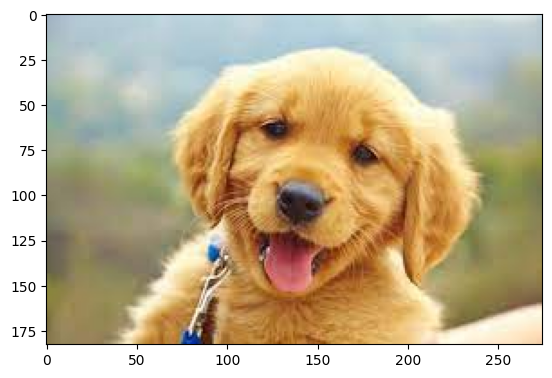

In [11]:
# Your code here
path2= r'C:\Users\habib\OneDrive\Desktop\gettingintoit\skyexperts CV training\Session2\images\dogBGR.jpg'
img2= cv.imread(path2)
cv.imshow('dog', img2)
cv.waitKey(2000)
cv.destroyAllWindows()
# Use cv.cvtColor()
img2_rgb = cv.cvtColor(img2, cv.COLOR_BGR2RGB)
cv.imshow('dog', img2_rgb)
plt.imshow(img2_rgb)
cv.waitKey(2000)
cv.destroyAllWindows()

### Task 10: Image Sharpening
Apply cv2.blur() with a 5x5 kernel, then use cv2.filter2D() with sharpening kernels of varying strengths (e.g., [[0, -1, 0], [-1, 5, -1], [0, -1, 0]] and [[0, -2, 0], [-2, 9, -2], [0, -2, 0]]).
Compare between original and sharpened image after blurring.

In [25]:
# Your code here
# Use cv2.blur
blured=cv.blur(img2, (5, 5))
# Define sharpen kernel, use cv.filter2D()
k_mild = np.array([[0, -1, 0],
                   [-1, 5, -1],
                   [0, -1, 0]])

k_strong = np.array([[0, -2, 0],
                     [-2, 9, -2],
                     [0, -2, 0]])
sharp_mild = cv.filter2D(blured, -1, k_mild)
sharp_strong = cv.filter2D(blured, -1, k_strong)

cv.imshow('blured', blured)
cv.imshow('mild', sharp_mild)
cv.imshow('strong', sharp_strong)

cv.waitKey(3000)
cv.destroyAllWindows()


### Task 11: Add Salt and Pepper Noise to Image
Implement a function to add salt and pepper noise to an image. Control noise density (e.g., 0.05).

In [ ]:
# Your code here
def add_salt_pepper_noise(image, density=0.05):
    # Implement using random pixels set to 0 or 255
    pass

# Apply to an image and display

### Task 12: Remove Salt and Pepper Noise Using Median Filter
Apply cv.medianBlur() to a noisy image. Experiment with kernel sizes (3,5,7) and compare results.

In [ ]:
# Your code here

### Task 13: Implement Adaptive Median Filter
Write a custom function for adaptive median filtering. It should dynamically increase window size until noise is removed or max size is reached. Apply to a noisy image and compare with standard median.

In [ ]:
# Your code here
def adaptive_median_filter(image, max_size=7):
    # Implement logic: for each pixel, start with small window, increase if needed
    pass

# Test on noisy image

### Task 14: Implement Bilateral Filter Function
Write a Python function to perform bilateral filtering on an image. Use Gaussian weights for both spatial and intensity. Parameters: diameter, sigma_color, sigma_space. Compare with cv.bilateralFilter().

In [ ]:
# Your code here
def custom_bilateral_filter(image, diameter, sigma_color, sigma_space):
    # Implement using nested loops or vectorized (efficiently)
    # For each pixel, compute weighted sum based on distance and intensity diff
    pass

# Apply to image, display, and compare with OpenCV's version

### [BONUS] Task 15: Comprehensive Camera Task 
Combine: Live camera feed -> grayscale -> add noise -> remove with median -> sharpen. Display all stages in separate windows.

In [ ]:
# To read video from camera example:

camera_id = 0
delay = 400
window_name = 'frame'

cap = cv.VideoCapture(camera_id)

if not cap.isOpened():
    sys.exit()

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    cv.imshow(window_name, frame)
    if cv.waitKey(delay) & 0xFF == ord('q'):
        break

cap.release()
cv.destroyWindow(window_name)


# Your code here

### [BONUS]Task 16: Comprehensive Video Task
Similar to Task 18 but for a video file. Save the final processed video.

In [ ]:
# Your code here

### Task 17: Performance Comparison
Time the execution of standard median vs adaptive median on a large noisy image. Discuss when adaptive median filter is better.

In [ ]:
import time
# Your code here
# Use time.time() to measure